# Ortalama Yalan Söyler: Grafiğe Bakmadan Karar Vermeyin

Medium makalesindeki tüm grafik ve rakamları üreten notebook.

**Veri:** NYC Taxi & Limousine Commission (TLC) kayıtlarından alınmış, Mart 2019’a ait 6.433 taksi yolculuğundan oluşan örneklem (seaborn `taxis` örnek veri seti) ve Anscombe Dörtlüsü (1973).

**Makale:** Medium linki README’de.

## Kurulum ve veri

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd()
OUT = BASE / "gorseller"
OUT.mkdir(exist_ok=True)
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"

# ---------- Görsel stil (üç makalede ortak) ----------
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
})


def save(fig, name):
    fig.savefig(OUT / name, dpi=200, bbox_inches="tight", pad_inches=0.35)
    plt.show()


def tl(x):  # 13.09 -> "13,09"
    return f"{x:.2f}".replace(".", ",")


df = pd.read_csv(DATA_URL, parse_dates=["pickup", "dropoff"])
print(f"Veri: {len(df):,} yolculuk, {df.pickup.min():%d.%m.%Y} – {df.pickup.max():%d.%m.%Y}")

Veri: 6,433 yolculuk, 28.02.2019 – 31.03.2019


## 1. Yolculuk ücreti: ortalama vs medyan
Ücret dağılımı sağa çarpık; ortalama ile medyan arasındaki farkı ve JFK–Manhattan sabit ücretini (52 $) inceliyoruz.


[Ücret] ortalama=$13.09 medyan=$9.50 ortalamanın altında=%70 p95=$37.00 max=$150 52$ olan=131 JFK–Manhattan(52$)=110 tüm JFK–Man 52$ mı=True


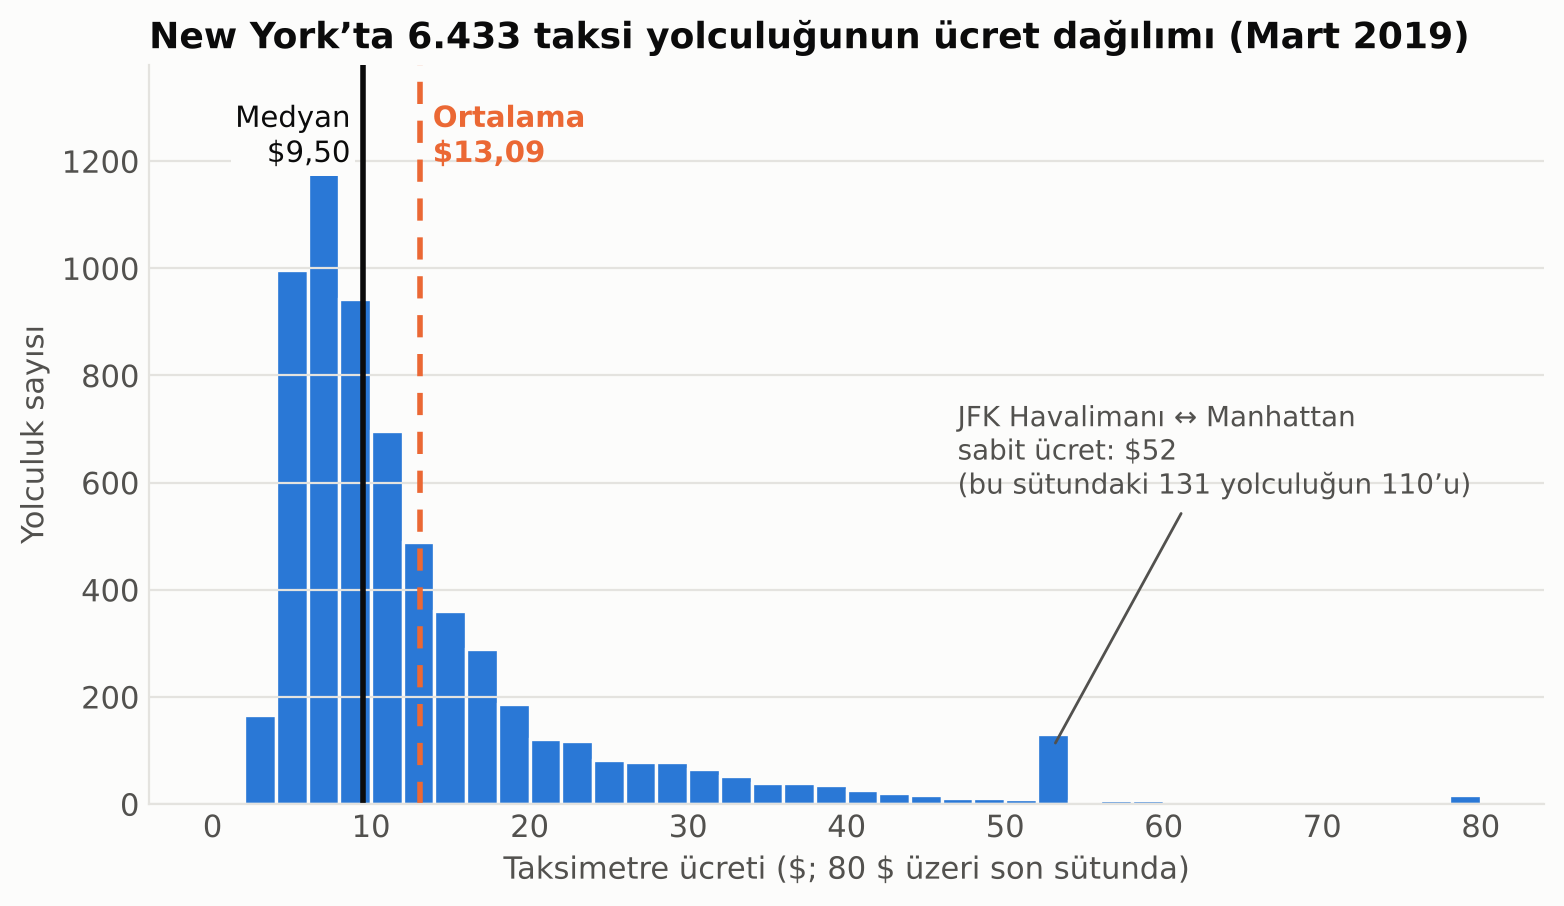

In [2]:
fare = df["fare"]
ort, med = fare.mean(), fare.median()
alti = (fare < ort).mean() * 100
p95 = fare.quantile(0.95)
sabit52 = (fare == 52).sum()
jfk_man = df["pickup_zone"].eq("JFK Airport") & df["dropoff_borough"].eq("Manhattan") | \
          df["dropoff_zone"].eq("JFK Airport") & df["pickup_borough"].eq("Manhattan")
jfk = int((jfk_man & (fare == 52)).sum())
jfk_tum52 = bool((fare[jfk_man] == 52).all())
print(f"\n[Ücret] ortalama=${ort:.2f} medyan=${med:.2f} ortalamanın altında=%{alti:.0f} "
      f"p95=${p95:.2f} max=${fare.max():.0f} 52$ olan={sabit52} JFK–Manhattan(52$)={jfk} tüm JFK–Man 52$ mı={jfk_tum52}")

fig, ax = plt.subplots(figsize=(9, 4.8))
bins = np.arange(0, 82, 2)
ax.hist(fare.clip(upper=80), bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.2)
ax.axvline(med, color=INK, lw=2)
ax.axvline(ort, color=ORANGE, lw=2, ls=(0, (4, 3)))
ymax = ax.get_ylim()[1]
ax.text(med - 0.8, ymax * 0.95, f"Medyan\n\\${tl(med)}", ha="right", va="top", color=INK, fontsize=10.5,
        bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
ax.text(ort + 0.8, ymax * 0.95, f"Ortalama\n\\${tl(ort)}", ha="left", va="top", color=ORANGE, fontsize=10.5, fontweight="bold")
ax.annotate(f"JFK Havalimanı ↔ Manhattan\nsabit ücret: \\$52\n(bu sütundaki {sabit52} yolculuğun {jfk}’u)",
            xy=(53, sabit52 * 0.8), xytext=(47, ymax * 0.42), color=INK_2, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=INK_2, lw=1))
ax.set_title("New York’ta 6.433 taksi yolculuğunun ücret dağılımı (Mart 2019)")
ax.set_xlabel("Taksimetre ücreti (\\$; 80 \\$ üzeri son sütunda)")
ax.set_ylabel("Yolculuk sayısı")
ax.grid(axis="x", visible=False)
save(fig, "01_taksi_ucret_ortalama_medyan.png")

## 2. Anscombe Dörtlüsü
Dört veri setinin özet istatistikleri aynı, grafikleri bambaşka (Anscombe, 1973).


[Anscombe]
            Ort. x  Ort. y  Var. x  Var. y  Korelasyon              Doğru
Veri seti                                                               
I             9.0     7.5    11.0    4.13        0.82  y = 3.00 + 0.500x
II            9.0     7.5    11.0    4.13        0.82  y = 3.00 + 0.500x
III           9.0     7.5    11.0    4.12        0.82  y = 3.00 + 0.500x
IV            9.0     7.5    11.0    4.12        0.82  y = 3.00 + 0.500x


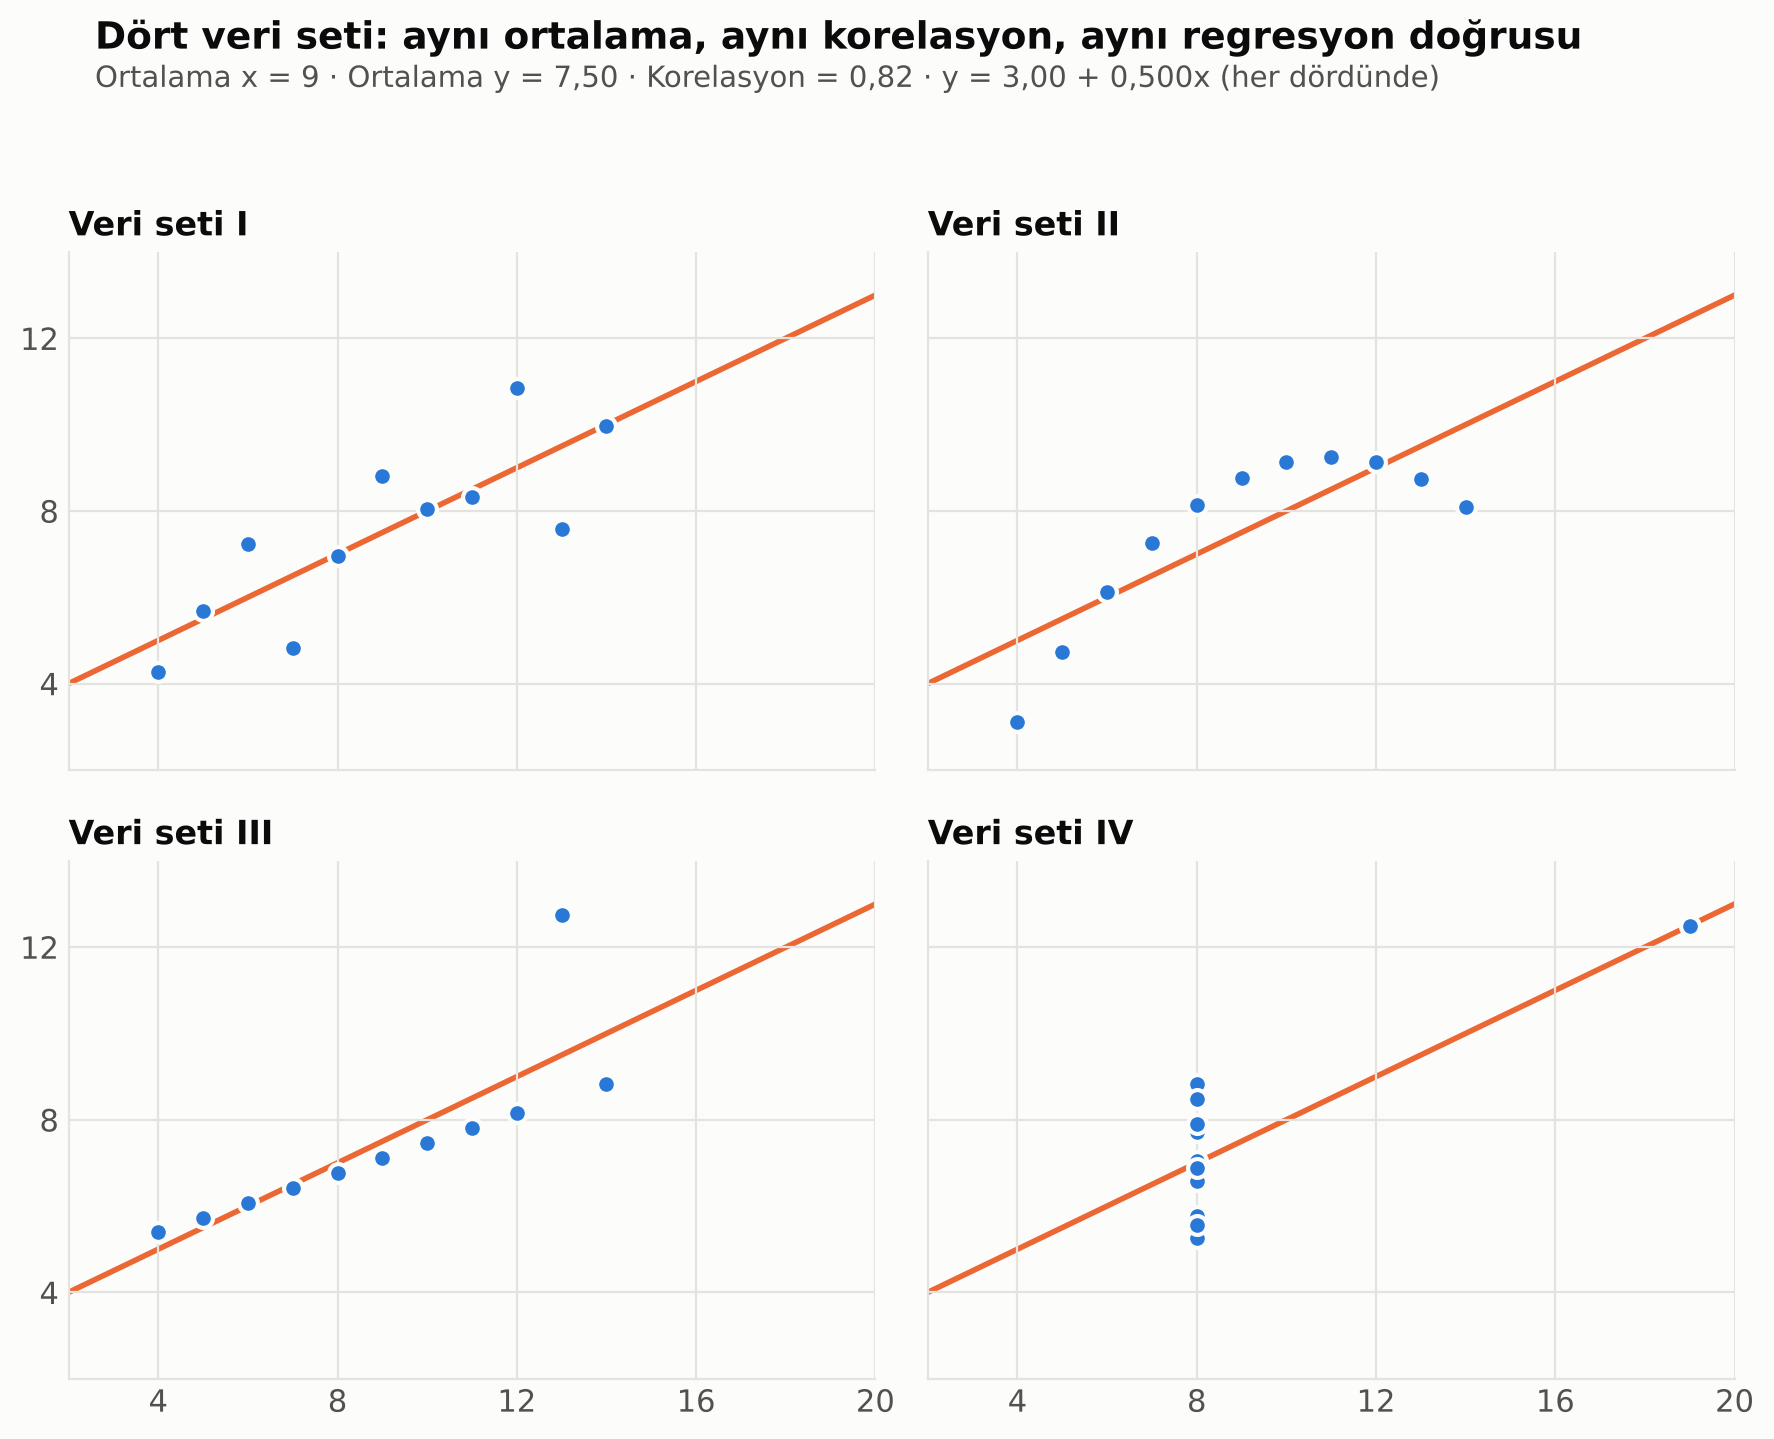

In [3]:
x123 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    "I":   (x123, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x123, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x123, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
            [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
rows = []
for k, (x, y) in anscombe.items():
    x, y = np.array(x), np.array(y)
    b, a = np.polyfit(x, y, 1)
    rows.append({"Veri seti": k, "Ort. x": x.mean(), "Ort. y": y.mean(),
                 "Var. x": x.var(ddof=1), "Var. y": y.var(ddof=1),
                 "Korelasyon": np.corrcoef(x, y)[0, 1], "Doğru": f"y = {a:.2f} + {b:.3f}x"})
print("\n[Anscombe]\n", pd.DataFrame(rows).set_index("Veri seti").round(2).to_string())

fig, axes = plt.subplots(2, 2, figsize=(9, 7.2), sharex=True, sharey=True)
xs = np.array([2, 20])
for ax, (k, (x, y)) in zip(axes.flat, anscombe.items()):
    b, a = np.polyfit(x, y, 1)
    ax.plot(xs, a + b * xs, color=ORANGE, lw=2, zorder=1)
    ax.scatter(x, y, s=46, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=2)
    ax.set_title(f"Veri seti {k}", fontsize=12)
    ax.set_xlim(2, 20); ax.set_ylim(2, 14)
    ax.set_xticks([4, 8, 12, 16, 20]); ax.set_yticks([4, 8, 12])
fig.suptitle("Dört veri seti: aynı ortalama, aynı korelasyon, aynı regresyon doğrusu",
             x=0.06, ha="left", fontsize=13.5, fontweight="bold", color=INK, y=0.995)
fig.text(0.06, 0.948, "Ortalama x = 9 · Ortalama y = 7,50 · Korelasyon = 0,82 · y = 3,00 + 0,500x (her dördünde)",
         color=INK_2, fontsize=10.5)
fig.tight_layout(rect=(0, 0, 1, 0.935), h_pad=1.6)
save(fig, "02_anscombe_dortlusu.png")

## 3. Bahşiş: ödeme yöntemi saklı grubu
TLC veri sözlüğüne göre bahşiş alanı yalnızca kredi kartı bahşişleri için otomatik doldurulur; nakit bahşişler kayda girmez.


[Bahşiş] tüm yolculuklarda ortalama bahşiş=$1.98  sıfır bahşiş=%36  sıfırların nakit payı=%78
  nakit: n=1812 bahşiş>0 olan=0
  kart: n=4577 medyan bahşiş oranı=%25.5  sıfır=%10  ortalama bahşiş=$2.78
  kart: bahşiş oranı %20–30 arası olan yolculuk payı=%46


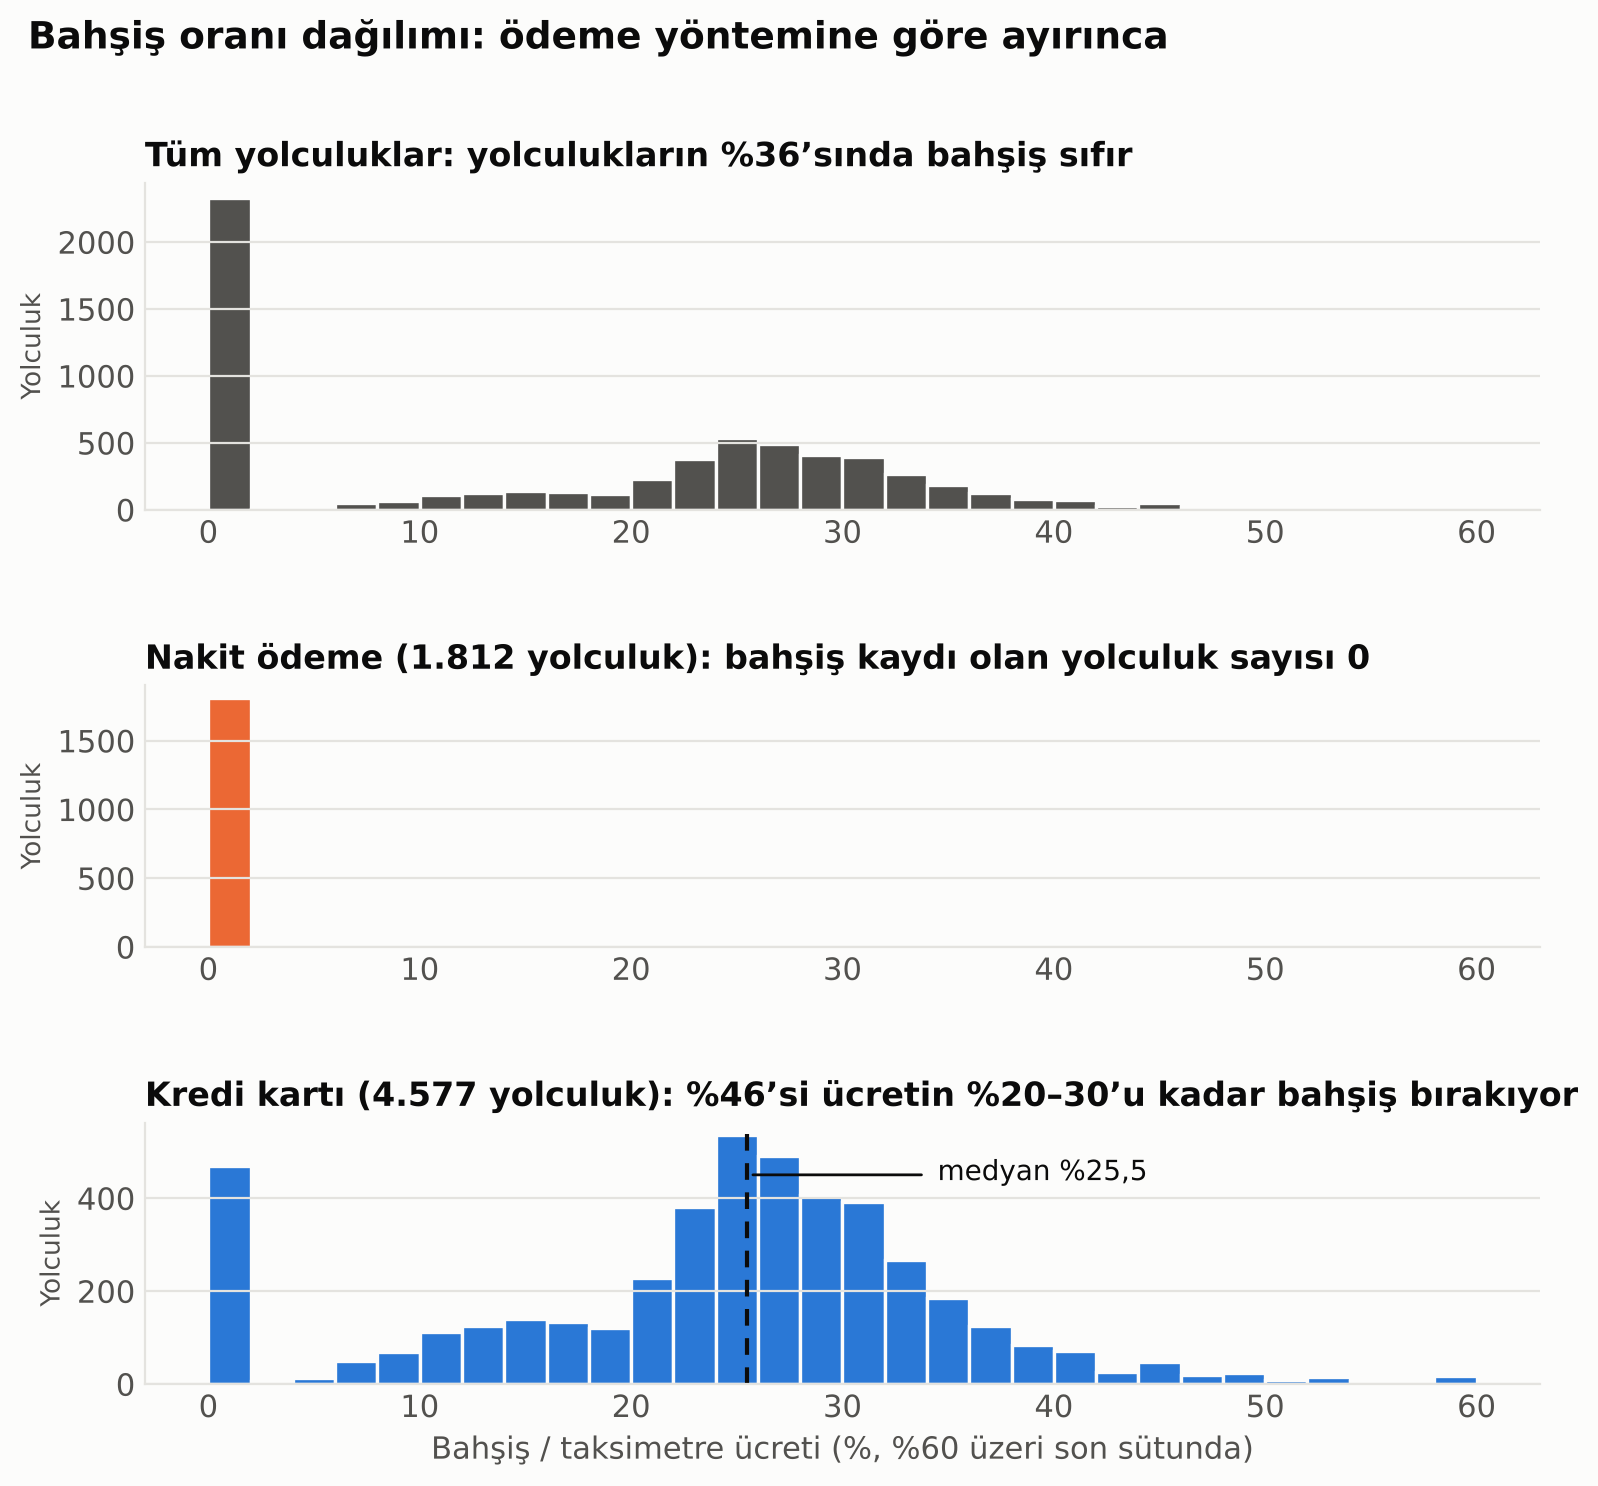


Görseller: gorseller/ klasörüne kaydedildi


In [4]:
t = df.dropna(subset=["payment"]).copy()
t["bahsis_orani"] = t["tip"] / t["fare"] * 100
sifir = (df["tip"] == 0)
sifir_pay = sifir.mean() * 100
sifir_nakit = (df.loc[sifir, "payment"] == "cash").mean() * 100
nakit = t[t.payment == "cash"]
kart = t[t.payment == "credit card"]
kart_med = kart["bahsis_orani"].median()
kart_sifir = (kart["tip"] == 0).mean() * 100
print(f"\n[Bahşiş] tüm yolculuklarda ortalama bahşiş=${df.tip.mean():.2f}  sıfır bahşiş=%{sifir_pay:.0f}  "
      f"sıfırların nakit payı=%{sifir_nakit:.0f}")
print(f"  nakit: n={len(nakit)} bahşiş>0 olan={int((nakit.tip > 0).sum())}")
print(f"  kart: n={len(kart)} medyan bahşiş oranı=%{kart_med:.1f}  sıfır=%{kart_sifir:.0f}  "
      f"ortalama bahşiş=${kart.tip.mean():.2f}")

bins = np.arange(0, 62, 2)
fig = plt.figure(figsize=(9, 7.8))
gs = fig.add_gridspec(3, 1, height_ratios=[1.25, 1, 1], hspace=0.62)
ax0 = fig.add_subplot(gs[0])
tum_oran = df["tip"] / df["fare"] * 100
ax0.hist(tum_oran.clip(upper=60), bins=bins, color=INK_2, edgecolor=SURFACE, linewidth=1.2)
ax0.set_title(f"Tüm yolculuklar: yolculukların %{sifir_pay:.0f}’sında bahşiş sıfır", fontsize=12)
ax1 = fig.add_subplot(gs[1], sharex=ax0)
ax1.hist(nakit["bahsis_orani"].clip(upper=60), bins=bins, color=ORANGE, edgecolor=SURFACE, linewidth=1.2)
ax1.set_title(f"Nakit ödeme ({len(nakit):,} yolculuk): bahşiş kaydı olan yolculuk sayısı 0".replace(",", "."), fontsize=12)
ax2 = fig.add_subplot(gs[2], sharex=ax0)
ax2.hist(kart["bahsis_orani"].clip(upper=60), bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.2)
ax2.axvline(kart_med, color=INK, lw=1.5, ls=(0, (4, 3)))
ax2.text(kart_med + 9, ax2.get_ylim()[1] * 0.78, f"medyan %{kart_med:.1f}".replace(".", ","), color=INK, fontsize=10)
ax2.annotate("", xy=(kart_med, ax2.get_ylim()[1] * 0.8), xytext=(kart_med + 8.5, ax2.get_ylim()[1] * 0.8),
             arrowprops=dict(arrowstyle="-", color=INK, lw=1))
kart_2030 = kart["bahsis_orani"].between(20, 30).mean() * 100
print(f"  kart: bahşiş oranı %20–30 arası olan yolculuk payı=%{kart_2030:.0f}")
ax2.set_title(f"Kredi kartı ({len(kart):,} yolculuk): %{kart_2030:.0f}’si ücretin %20–30’u kadar bahşiş bırakıyor".replace(",", "."), fontsize=12)
for ax in (ax0, ax1, ax2):
    ax.grid(axis="x", visible=False); ax.set_ylabel("Yolculuk", fontsize=9.5)
ax2.set_xlabel("Bahşiş / taksimetre ücreti (%, %60 üzeri son sütunda)")
fig.suptitle("Bahşiş oranı dağılımı: ödeme yöntemine göre ayırınca",
             x=0.06, ha="left", fontsize=13.5, fontweight="bold", color=INK, y=0.985)
save(fig, "03_bahsis_odeme_yontemi.png")

print("\nGörseller: gorseller/ klasörüne kaydedildi")

### Anscombe özet tablosu (görsel)
Medium tablo desteklemediği için tablo görsel olarak üretiliyor.

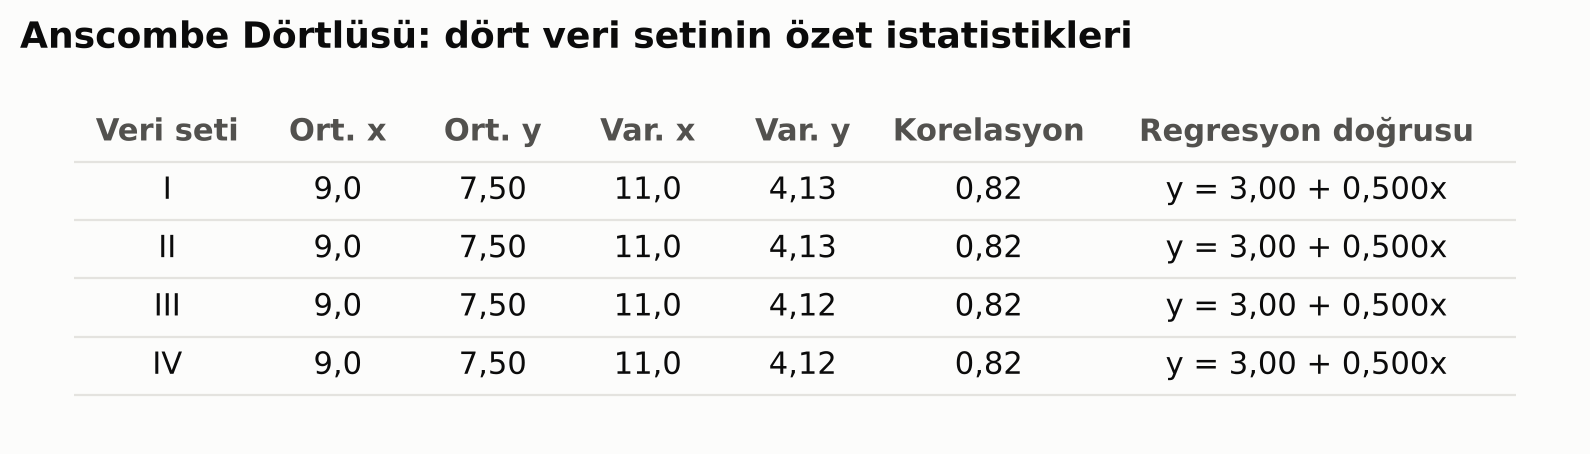

In [5]:
tbl = pd.DataFrame(rows)
cells = [[r["Veri seti"], f"{r['Ort. x']:.1f}", f"{r['Ort. y']:.2f}", f"{r['Var. x']:.1f}",
          f"{r['Var. y']:.2f}", f"{r['Korelasyon']:.2f}", r["Doğru"]] for r in rows]
cells = [[c.replace(".", ",") if i < 6 else c.replace("3.00", "3,00").replace("0.500", "0,500") for i, c in enumerate(row)] for row in cells]
cols = ["Veri seti", "Ort. x", "Ort. y", "Var. x", "Var. y", "Korelasyon", "Regresyon doğrusu"]
fig, ax = plt.subplots(figsize=(10, 2.4))
ax.axis("off")
tb = ax.table(cellText=cells, colLabels=cols, loc="center", cellLoc="center",
              colWidths=[.12, .1, .1, .1, .1, .14, .27])
tb.auto_set_font_size(False); tb.set_fontsize(11); tb.scale(1, 1.75)
for (r_, c_), cell in tb.get_celld().items():
    cell.set_edgecolor(GRID); cell.set_linewidth(0.8)
    cell.visible_edges = "B"
    if r_ == 0:
        cell.set_text_props(color=INK_2, fontweight="bold"); cell.set_facecolor(SURFACE)
    else:
        cell.set_facecolor(SURFACE); cell.set_text_props(color=INK)
ax.set_title("Anscombe Dörtlüsü: dört veri setinin özet istatistikleri", pad=6)
save(fig, "02a_anscombe_tablo.png")